<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup, model and attribution](README.md)

# 01 · When should a translation pipeline hold a row for review?

A translation pipeline needs more than a translated string. It must preserve the original text, keep IDs stable, distinguish missing text from blank text, and decide which language detections it is willing to act on. We will normalize an authored collection of messages toward English while retaining every row and an explicit routing decision.

**All 15 messages are synthetic examples**, not customer data. The worker performs real local language detection and neural translation. There is no translation API or replay mode. First setup downloads one SHA256-pinned Argos Spanish→English package (285 MB) plus 1.7 MB of pinned Stanza assets; subsequent inference uses that local model. Nothing in the charts measures translation accuracy or calibrated detection confidence.

## Set a simple review threshold

`MIN_CHARS` is an integer from **1 to 30 Unicode characters**, default **20**; the experiment uses **5**. It applies to trimmed text length, not bytes or tokens. Shorter nonblank messages are held for review before language routing. This is a demonstration policy, not a validated confidence threshold.

Only detected **English (`en`)** and **Spanish (`es`)** are eligible. English passes through; Spanish is translated to English. Other detected codes are held for review, so this example cannot trigger downloads for arbitrary language pairs. Missing and blank input have separate outcomes. Restart Kernel → Run All after editing.

In [1]:
MIN_CHARS = 20  # Trimmed Unicode-character threshold; experiment: 5

In [2]:
import hashlib
import json
import os
from pathlib import Path
from tempfile import TemporaryDirectory

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator

from prepare_model import ResourceManifestServer, prepare_model

assert type(MIN_CHARS) is int and 1 <= MIN_CHARS <= 30
model_dir, model_manifest = prepare_model()
model_index = ResourceManifestServer(model_dir, model_manifest, Path("artifacts"))
settings = {
    "VGI_TRANSLATE_BACKEND": "argos",
    "ARGOS_PACKAGES_DIR": str(model_dir),
    "ARGOS_COMPUTE_TYPE": "float32",
    "ARGOS_DEVICE_TYPE": "cpu",
    "ARGOS_CHUNK_TYPE": "ARGOSTRANSLATE",
    "ARGOS_MODEL_PROVIDER": "OPENNMT",
    "ARGOS_BEAM_SIZE": "4",
    "ARGOS_INTRA_THREADS": "1",
    "STANZA_RESOURCES_URL": model_index.url,
    "STANZA_RESOURCES_VERSION": "1.10.0",
}
previous = {key: os.environ.get(key) for key in settings}
os.environ.update(settings)
secret_dir = TemporaryDirectory(prefix="translate-notebook-secrets-")
con = haybarn.connect(config={"secret_directory": secret_dir.name, "allow_persistent_secrets": False})
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"Synthetic authored messages · minimum {MIN_CHARS} characters · Argos es→en 1.9 / float32 CPU · no quality scoring",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.93))
    plt.show()


%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-translate/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-translate/notebooks/pyproject.toml.

## Detect once and retain the original corpus

The literal remote revision includes the worker's float32 portability fix. Setup verifies the model archive and extracted files against the committed manifest, using a private cache; existing global Argos models are not required. Stanza 1.10.1 requires an updated resource index and Spanish tokenizer/multiword-token assets beyond the older files bundled in Argos. Setup pins those three official assets too. Stanza's supported resource-URL setting points to a bounded loopback server serving the pinned 1.10.0 index. No library or worker implementation is patched. The cache helper downloads model assets only; SQL still calls the real worker for every detection and translation.

Materialize detection results before routing. `detect_lang` returns a code, with no confidence column. The reference view supplies human-readable names where available; it is not an exhaustive list or a promise that every language pair is installed.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'translate' AS tr (
 TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-translate.git@332e36901e8292b58a0bc6794703b10dfac6dece --constraints worker-constraints.txt vgi-translate-worker'
);
CREATE TABLE messages AS SELECT * FROM (VALUES
 (1,'Long Spanish','El envío llegó tarde y la caja estaba dañada.'),
 (2,'Long English','Great product, works as described.'),
 (3,'Long Spanish','Muy buena calidad, lo recomiendo.'),
 (4,'Long English','The refund arrived after three days.'),
 (5,'Long French','Le colis est arrivé hier et il était intact.'),
 (6,'Short text','Gracias.'),(7,'Short text','Hello!'),
 (8,'Short text','No.'),(9,'Short text','Pie.'),
 (10,'Blank',''),(11,'Blank','   '),(12,'Missing',NULL),
 (13,'Short text','Hola.'),(14,'Short text','Sale ends tomorrow.'),
 (15,'Short text','Buen producto.')
) AS m(id,input_case,body);
CREATE TABLE detected AS SELECT *,length(trim(body)) AS input_chars,
 tr.detect_lang(body) AS detected_code FROM messages;
CREATE TABLE routed AS SELECT *,
 CASE WHEN body IS NULL THEN 'Missing'
 WHEN trim(body)='' THEN 'Blank'
 WHEN input_chars<{{MIN_CHARS}} THEN 'Short: review'
 WHEN detected_code IS NULL OR detected_code NOT IN ('en','es') THEN 'Language: review'
 WHEN detected_code='en' THEN 'English: unchanged'
 ELSE 'Spanish: translate' END AS route
FROM detected;

,Count


In [4]:
%%sql inventory <<
SELECT d.id,d.input_case,d.body,d.input_chars,d.detected_code,l.name AS detected_language,d.route
FROM routed d LEFT JOIN tr.languages l ON l.code=d.detected_code ORDER BY d.id;

In [5]:
display(inventory)
corpus = con.execute("SELECT * FROM detected ORDER BY id").df()
fingerprint = hashlib.sha256(corpus.to_json(orient="records").encode()).hexdigest()
assert not inventory.id.duplicated().any() and len(inventory) == 15
assert inventory.loc[inventory.body.isna(), "route"].eq("Missing").all()
prose(
    f"The corpus contains **{len(inventory)} rows**, including **{inventory.body.isna().sum()} missing value**. Every original ID survives detection. Corpus/detection fingerprint: `{fingerprint}`. Model archive SHA256: `{model_manifest['sha256']}`. The short strings' displayed codes are predictions from their limited text, not authoritative language labels; no numeric confidence is exposed."
)

,id,input_case,body,input_chars,detected_code,detected_language,route
0,1,Long Spanish,El envío llegó tarde y la caja estaba dañada.,45,es,Spanish,Spanish: translate
1,2,Long English,"Great product, works as described.",34,en,English,English: unchanged
2,3,Long Spanish,"Muy buena calidad, lo recomiendo.",33,es,Spanish,Spanish: translate
3,4,Long English,The refund arrived after three days.,36,en,English,English: unchanged
4,5,Long French,Le colis est arrivé hier et il était intact.,44,fr,French,Language: review
5,6,Short text,Gracias.,8,es,Spanish,Short: review
6,7,Short text,Hello!,6,br,None,Short: review
7,8,Short text,No.,3,sr,None,Short: review
8,9,Short text,Pie.,4,pl,Polish,Short: review
9,10,Blank,,0,und,None,Blank


The corpus contains **15 rows**, including **1 missing value**. Every original ID survives detection. Corpus/detection fingerprint: `62e3467d53b589fea575612fb69422af5bf825e5d08be4c1b893033cf9bb60fe`. Model archive SHA256: `c54df2b62fceaf54a3ce5d97db6bf56efd7940063329f6778f4212d2acb370d4`. The short strings' displayed codes are predictions from their limited text, not authoritative language labels; no numeric confidence is exposed.

## Translate only admitted rows, then join them back

`translate_all` accepts exactly one text column plus an optional ID column. Its `id` argument carries the original key through; the `source='auto'` result reports the source actually used. We admit only the two allowed detected languages. English is returned unchanged by the backend; Spanish uses the pinned model.

Rows held for review get **NULL normalized output with an explicit review route**, while their original text stays available. A missing original is also NULL but labeled Missing; blank strings retain their exact original whitespace. This prevents a downstream consumer from treating “not translated” as an empty successful translation.

In [6]:
%%sql
CREATE TABLE translated AS SELECT * FROM tr.translate_all(
 (SELECT id,body FROM routed WHERE route IN ('English: unchanged','Spanish: translate') ORDER BY id),
 id := 'id',target := 'en',source := 'auto'
);
CREATE TABLE normalized AS SELECT r.*,t.src_lang AS used_source,
 CASE WHEN route='Blank' THEN body ELSE t.translation END AS normalized_text,
 t.text AS worker_input
FROM routed r LEFT JOIN translated t USING(id);

,Count


In [7]:
%%sql result <<
SELECT id,input_case,body,detected_code,route,used_source,normalized_text
FROM normalized ORDER BY id;

In [8]:
display(result)
resource_requests = json.loads(Path("artifacts/resource-requests.json").read_text())
assert 1 <= len(resource_requests) <= 4 and all(r["status"] == 200 for r in resource_requests)
assert all(
    r["sha256"] == model_manifest["runtime_files"]["translate-es_en-1_9/stanza/resources.json"]
    for r in resource_requests
)
assert len(result) == len(inventory) and result.id.tolist() == inventory.id.tolist()
checks = con.execute("""SELECT
 count(*) FILTER(WHERE route IN ('English: unchanged','Spanish: translate') AND (normalized_text IS NULL OR worker_input IS DISTINCT FROM body OR used_source IS DISTINCT FROM detected_code)),
 count(*) FILTER(WHERE route='English: unchanged' AND normalized_text IS DISTINCT FROM body),
 count(*) FILTER(WHERE route='Blank' AND normalized_text IS DISTINCT FROM body),
 count(*) FILTER(WHERE route IN ('Missing','Short: review','Language: review') AND normalized_text IS NOT NULL)
 FROM normalized""").fetchone()
assert checks == (0, 0, 0, 0)
assert con.execute("SELECT count(*)=count(DISTINCT id) FROM translated").fetchone()[0]
translated_count = int(result.route.eq("Spanish: translate").sum())
unchanged_count = int(result.route.eq("English: unchanged").sum())
review_count = int(result.route.str.contains("review").sum())
prose(
    f"At **{MIN_CHARS} characters**, **{translated_count} rows enter Spanish→English translation**, **{unchanged_count} English rows pass through**, and **{review_count} rows are held for review**. Missing and blank rows remain separate. ID uniqueness, original-text passthrough and language-routing consistency all pass. A nonempty translation is evidence of successful execution, not proof that its meaning is correct; inspect the paired text above."
)

,id,input_case,body,detected_code,route,used_source,normalized_text
0,1,Long Spanish,El envío llegó tarde y la caja estaba dañada.,es,Spanish: translate,es,The shipment was late and the box was damaged.
1,2,Long English,"Great product, works as described.",en,English: unchanged,en,"Great product, works as described."
2,3,Long Spanish,"Muy buena calidad, lo recomiendo.",es,Spanish: translate,es,"Very good quality, I recommend."
3,4,Long English,The refund arrived after three days.,en,English: unchanged,en,The refund arrived after three days.
4,5,Long French,Le colis est arrivé hier et il était intact.,fr,Language: review,None,None
5,6,Short text,Gracias.,es,Short: review,None,None
6,7,Short text,Hello!,br,Short: review,None,None
7,8,Short text,No.,sr,Short: review,None,None
8,9,Short text,Pie.,pl,Short: review,None,None
9,10,Blank,,und,Blank,None,


At **20 characters**, **2 rows enter Spanish→English translation**, **2 English rows pass through**, and **8 rows are held for review**. Missing and blank rows remain separate. ID uniqueness, original-text passthrough and language-routing consistency all pass. A nonempty translation is evidence of successful execution, not proof that its meaning is correct; inspect the paired text above.

## Audit the policy population

Count every route against the whole corpus. The short-text threshold runs before the language allowlist, so lowering it can move a row from “Short: review” to either an admitted route or “Language: review.” That is a policy reclassification, not a change in the language detector or an improvement in model quality.

In [9]:
%%sql routes <<
WITH categories(route,route_order) AS (VALUES
 ('Spanish: translate',1),('English: unchanged',2),('Short: review',3),
 ('Language: review',4),('Blank',5),('Missing',6))
SELECT c.route,c.route_order,count(n.id) AS rows
FROM categories c LEFT JOIN normalized n USING(route)
GROUP BY c.route,c.route_order ORDER BY c.route_order;

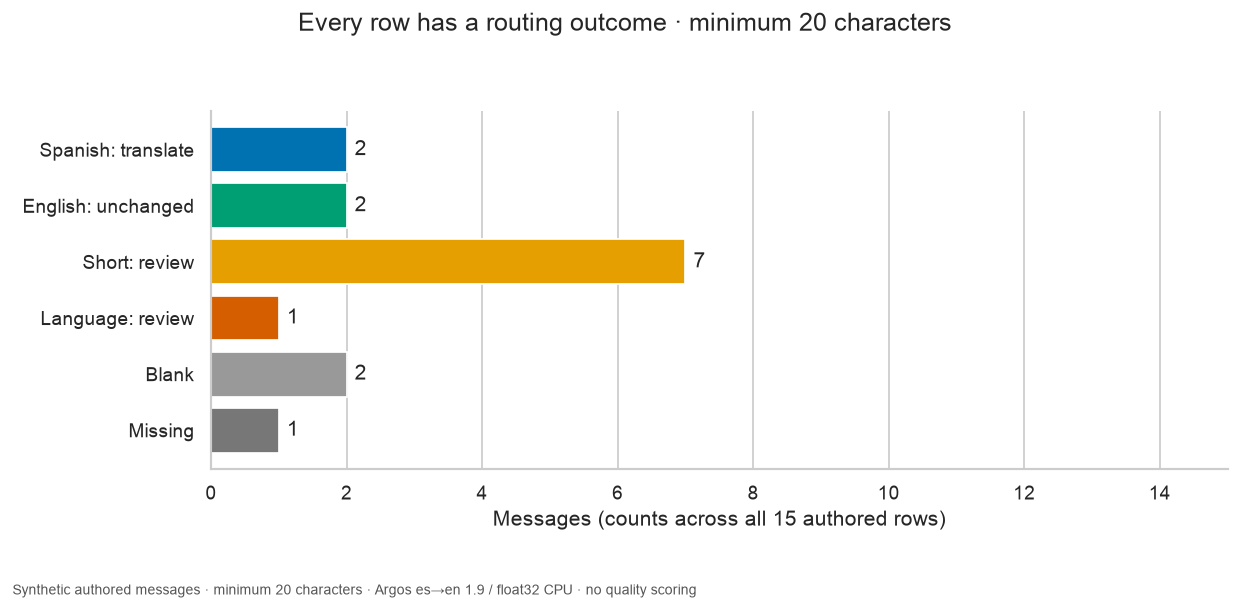

In [10]:
assert routes.rows.sum() == len(result)
colors = ["#0072b2", "#009e73", "#e69f00", "#d55e00", "#999999", "#777777"]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(routes.route, routes.rows, color=colors)
for i, row in enumerate(routes.itertuples()):
    ax.text(row.rows + 0.12, i, str(row.rows), va="center")
ax.invert_yaxis()
ax.set(xlabel="Messages (counts across all 15 authored rows)", xlim=(0, len(result)))
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
fig.suptitle(f"Every row has a routing outcome · minimum {MIN_CHARS} characters")
finish(fig)

## A text-length audit is not a quality score

Compare Unicode character counts for admitted inputs and outputs. A translation may expand or contract without getting better or worse; equal lengths do not establish semantic equivalence. English pass-through rows should lie on top of their original markers. Review, blank and missing rows are omitted from this chart and remain visible in the full table.

The paired text table is the primary review artifact. This chart is useful for spotting empty outputs or extreme expansion that deserve inspection, not for ranking translation accuracy.

In [11]:
%%sql lengths <<
SELECT id,route,length(body) AS source_chars,length(normalized_text) AS output_chars,
 length(normalized_text)-length(body) AS change_chars
FROM normalized WHERE route IN ('Spanish: translate','English: unchanged') ORDER BY id;

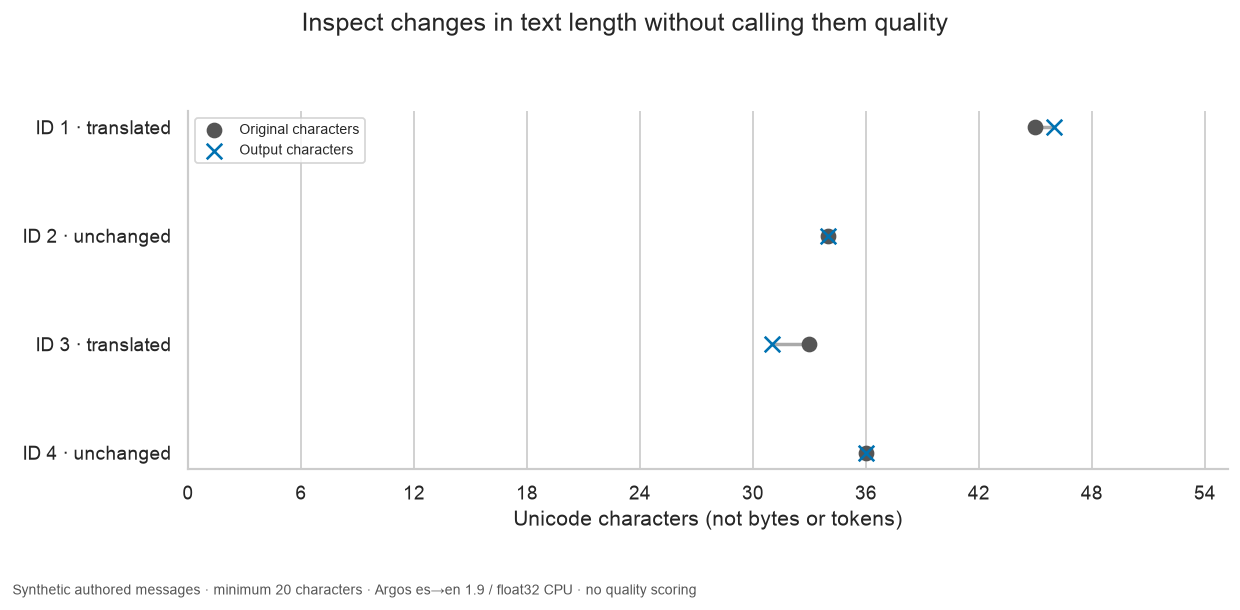

For the **2 translated rows**, output-minus-input length ranges from **-2 to +1 characters**. This measures string length only. The **2 admitted English rows** are byte-for-byte unchanged as checked above. The corpus is small and authored; its route proportions do not estimate a real workload's language mix or error rate.

5045

In [12]:
assert len(lengths) == translated_count + unchanged_count
assert lengths.output_chars.gt(0).all()
fig, ax = plt.subplots(figsize=(10, 4.8))
positions = np.arange(len(lengths))
for pos, row in zip(positions, lengths.itertuples(), strict=True):
    ax.plot([row.source_chars, row.output_chars], [pos, pos], color="#aaaaaa", lw=2)
ax.scatter(
    lengths.source_chars, positions, color="#555555", marker="o", s=65, label="Original characters", zorder=3
)
ax.scatter(
    lengths.output_chars, positions, color="#0072b2", marker="x", s=80, label="Output characters", zorder=4
)
ax.set(
    yticks=positions,
    yticklabels=[
        f"ID {r.id} · {'translated' if r.route.startswith('Spanish') else 'unchanged'}"
        for r in lengths.itertuples()
    ],
    xlabel="Unicode characters (not bytes or tokens)",
    xlim=(0, max(1, lengths[["source_chars", "output_chars"]].max().max()) * 1.2),
)
ax.invert_yaxis()
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
ax.legend(loc="best", fontsize=8)
fig.suptitle("Inspect changes in text length without calling them quality")
finish(fig)
changes = lengths.loc[lengths.route.eq("Spanish: translate"), "change_chars"]
prose(
    f"For the **{len(changes)} translated rows**, output-minus-input length ranges from **{changes.min():+d} to {changes.max():+d} characters**. This measures string length only. The **{unchanged_count} admitted English rows** are byte-for-byte unchanged as checked above. The corpus is small and authored; its route proportions do not estimate a real workload's language mix or error rate."
)
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-audit.json").write_text(
    json.dumps(
        {
            "min_chars": MIN_CHARS,
            "fingerprint": fingerprint,
            "model_sha256": model_manifest["sha256"],
            "runtime_cache_key": model_dir.name,
            "routes": routes.to_dict(orient="records"),
            "result": json.loads(result.to_json(orient="records")),
            "lengths": lengths.to_dict(orient="records"),
            "worker_checks": checks,
            "resource_requests": resource_requests,
        },
        indent=2,
    )
)

## Experiment: admit shorter messages

Change only `MIN_CHARS` from **20 to 5**. Predict that fewer rows remain in “Short: review,” but some will instead move to “Language: review.” Compare the route counts, exact newly admitted text pairs and length chart. The corpus/detection fingerprint and model SHA256 must stay unchanged; rows admitted under both thresholds should keep identical outputs in this pinned environment. Restore **20** afterwards.

A shorter threshold trades more automatic processing for less textual evidence per decision. This example does not establish an optimal threshold, calibrated detection confidence, semantic fidelity, or a production review policy. A real deployment needs representative evaluation data and human language review.

In [13]:
con.close()
prepare_model()  # Recheck every model member after inference, including the pinned Stanza runtime assets.
model_index.close()
secret_dir.cleanup()
for key, value in previous.items():
    if value is None:
        os.environ.pop(key, None)
    else:
        os.environ[key] = value

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)